# Customer Segmentation Analysis (RFM + K-Means)

**Oasis Infobyte SIP | Data Analytics | Level 1 - Task 2**

**Objective:** Segment e-commerce customers by purchasing behaviour using RFM analysis and K-Means clustering, then recommend a marketing action for each segment.

**Dataset:** [Online Retail (UCI Machine Learning Repository)](https://archive.ics.uci.edu/dataset/352/online+retail) - UK-based online retail transactions, 01/12/2010 to 09/12/2011 (CC BY 4.0).

**Steps:** load and clean the data, descriptive statistics, RFM features, scaling, Elbow method and silhouette score, K-Means, cluster visualisation and profiling, marketing insights.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Load and inspect the data

In [2]:
# Raw data: Online Retail.xlsx must be in the same folder as this notebook
df_raw = pd.read_excel("Online Retail.xlsx")
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


In [3]:
df_raw.info()

print("\nMissing values per column:")
print(df_raw.isnull().sum())

print("\nDuplicate rows:", df_raw.duplicated().sum())

df_raw.describe()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB

Missing values per column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows: 5268


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,"541,909.00",541909,"541,909.00","406,829.00"
mean,9.55,2011-07-04 13:34:57.156386,4.61,"15,287.69"
min,"-80,995.00",2010-12-01 08:26:00,"-11,062.06","12,346.00"
25%,1.00,2011-03-28 11:34:00,1.25,"13,953.00"
50%,3.00,2011-07-19 17:17:00,2.08,"15,152.00"
75%,10.00,2011-10-19 11:27:00,4.13,"16,791.00"
max,"80,995.00",2011-12-09 12:50:00,"38,970.00","18,287.00"
std,218.08,NaN,96.76,"1,713.60"


**Observations (raw data)**
- The dataset has 541,909 rows and 8 columns.
- `CustomerID` is missing in about 135,000 rows, and `Description` in about 1,450 rows.
- There are around 5,000 fully duplicated rows.
- `Quantity` and `UnitPrice` contain negative values, which come from returns, cancellations and adjustments.

## 2. Data cleaning

**Decisions**
- Removed rows with missing `CustomerID` (customer-level RFM is impossible without it).
- Removed exact duplicate rows.
- Removed cancelled invoices (`InvoiceNo` starting with "C").
- Removed rows with `Quantity <= 0` or `UnitPrice <= 0` (returns and data errors).
- Converted `CustomerID` to integer and `InvoiceDate` to datetime.
- Created `TotalPrice = Quantity x UnitPrice`.

In [4]:
df = df_raw.copy()   # always start from the raw data so this cell can be re-run safely

# 1. Drop rows without CustomerID
df = df.dropna(subset=["CustomerID"])

# 2. Drop exact duplicate rows
df = df.drop_duplicates()

# 3. Drop cancelled invoices (InvoiceNo starts with "C")
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

# 4. Drop non-positive quantities and prices (returns / data errors)
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

# 5. Fix data types and create the revenue column
df["CustomerID"] = df["CustomerID"].astype(int)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

# Before vs after summary
summary = pd.DataFrame({
    "Before": [len(df_raw), df_raw["CustomerID"].isnull().sum(),
               df_raw.duplicated().sum(), df_raw["CustomerID"].nunique()],
    "After":  [len(df), df["CustomerID"].isnull().sum(),
               df.duplicated().sum(), df["CustomerID"].nunique()],
}, index=["Rows", "Missing CustomerID", "Duplicate rows", "Unique customers"])
summary

,Before,After
Rows,541909,392692
Missing CustomerID,135080,0
Duplicate rows,5268,0
Unique customers,4372,4338


**Observations (after cleaning)**
- Rows dropped from 541,909 to 392,692 (149,217 removed).
- 4,338 unique customers remain for segmentation.
- No missing `CustomerID` values or duplicate rows are left.

## 3. Descriptive statistics

In [5]:
# Order level: total value of each invoice
order_values = df.groupby("InvoiceNo")["TotalPrice"].sum()

# Customer level: total spend and number of orders
customer_stats = df.groupby("CustomerID").agg(
    total_spent=("TotalPrice", "sum"),
    num_orders=("InvoiceNo", "nunique"),
)

print(f"Average order value: £{order_values.mean():,.2f}")
print(f"Average purchase frequency per customer: {customer_stats['num_orders'].mean():.2f} orders")
print(f"Average customer lifetime value (total spent): £{customer_stats['total_spent'].mean():,.2f}")

Average order value: £479.56
Average purchase frequency per customer: 4.27 orders
Average customer lifetime value (total spent): £2,048.69


**Observations**
- The average order value is £479.56, and a customer places 4.27 orders on average.
- The average customer lifetime value is £2,048.69 over the period covered by the data.
- These averages hide big differences between customers, which is exactly what segmentation will uncover.

## 4. Feature selection: RFM

Three behavioural features describe each customer:
- **Recency:** days since the customer's last purchase (lower is better).
- **Frequency:** number of distinct orders (higher is better).
- **Monetary:** total amount spent (higher is better).

In [6]:
# Reference date: one day after the last transaction in the data
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum"),
).reset_index()

print(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))
rfm.head()

       Recency  Frequency   Monetary
count 4,338.00   4,338.00   4,338.00
mean     92.54       4.27   2,048.69
std     100.01       7.70   8,985.23
min       1.00       1.00       3.75
25%      18.00       1.00     306.48
50%      51.00       2.00     668.57
75%     142.00       5.00   1,660.60
max     374.00     209.00 280,206.02


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,"77,183.60"
1,12347,2,7,"4,310.00"
2,12348,75,4,"1,797.24"
3,12349,19,1,"1,757.55"
4,12350,310,1,334.40


## 5. Normalisation

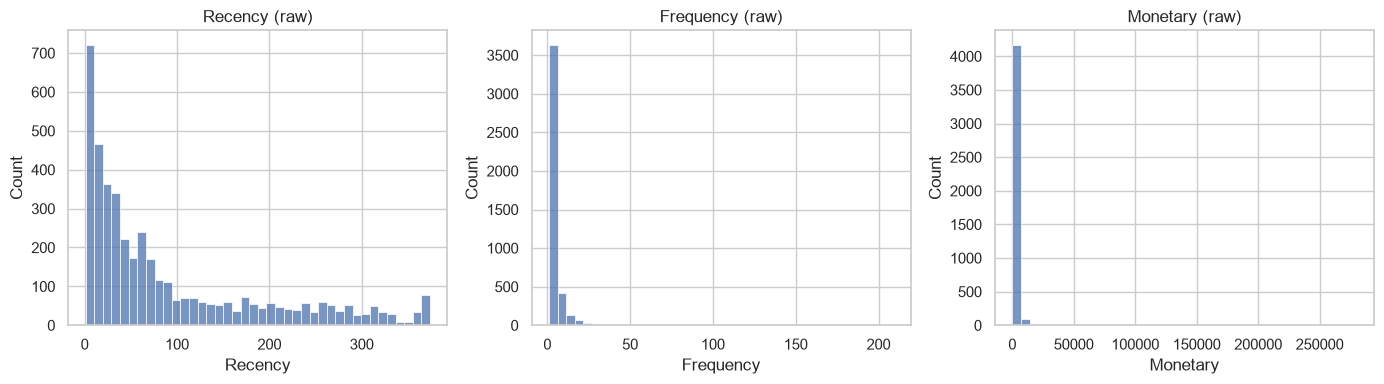

In [7]:
# Distribution of the raw RFM features
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm[col], bins=40, ax=ax)
    ax.set_title(f"{col} (raw)")
plt.tight_layout()
plt.show()

**Observation:** Frequency and Monetary are strongly right-skewed (most customers buy rarely and spend little, a few buy a lot). Recency is also skewed toward recent buyers. K-Means is distance based, so extreme values would dominate the clusters. A `log1p` transform is applied first, then `StandardScaler`, so every feature has mean 0 and standard deviation 1.

In [8]:
rfm_log = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])

scaler = StandardScaler()
X = scaler.fit_transform(rfm_log)

print("Scaled matrix shape:", X.shape)
print("Mean per feature:", X.mean(axis=0).round(2))
print("Std per feature :", X.std(axis=0).round(2))

Scaled matrix shape: (4338, 3)
Mean per feature: [-0. -0. -0.]
Std per feature : [1. 1. 1.]


## 6. Choosing the number of clusters (K)

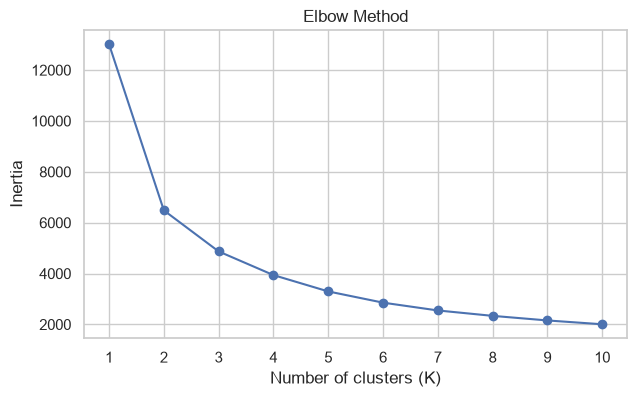

In [9]:
# Elbow method
inertia = []
K_range = range(1, 11)
for k in K_range:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    inertia.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(K_range, inertia, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(K_range)
plt.show()

In [10]:
# Silhouette score for K = 2 to 6
for k in range(2, 7):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X)
    print(f"K={k}  silhouette = {silhouette_score(X, labels):.3f}")

K=2  silhouette = 0.433
K=3  silhouette = 0.337
K=4  silhouette = 0.338
K=5  silhouette = 0.316
K=6  silhouette = 0.312


**Choosing K**

The Elbow curve drops sharply from K=1 to K=2 and keeps flattening gradually after K=3 to K=4.
Silhouette scores: K=2 (0.433), K=3 (0.337), K=4 (0.338), K=5 (0.316), K=6 (0.312).

K=2 has the highest score, but it only separates active from inactive customers, which is too coarse for targeted marketing. K=3 and K=4 score almost the same, so the simpler **K=3** was chosen: three clear segments that are easy to act on.

## 7. K-Means clustering and cluster profiling

In [11]:
K = 3
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(X)

# Average RFM values and revenue share per cluster
profile = rfm.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum"),
).round(1)
profile["Customer_Share_%"] = (profile["Customers"] / profile["Customers"].sum() * 100).round(1)
profile["Revenue_Share_%"] = (profile["Total_Revenue"] / profile["Total_Revenue"].sum() * 100).round(1)

# Name the segments by average spend (works for K=3: highest, middle, lowest)
rank = profile["Avg_Monetary"].sort_values(ascending=False).index.tolist()
segment_names = {
    rank[0]: "Champions",
    rank[1]: "Regular / Potential Loyalists",
    rank[2]: "Lapsed / Low-Value",
}
profile.insert(0, "Segment", profile.index.map(segment_names))
rfm["Segment"] = rfm["Cluster"].map(segment_names)

profile.sort_values("Avg_Monetary", ascending=False)

,Segment,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Customer_Share_%,Revenue_Share_%
Cluster,,,,,,,,
0,Champions,769,17.10,13.30,"7,898.50","6,073,917.30",17.70,68.30
2,Regular / Potential Loyalists,1697,44.20,3.40,"1,259.60","2,137,506.30",39.10,24.10
1,Lapsed / Low-Value,1872,167.40,1.40,361.00,"675,785.40",43.20,7.60


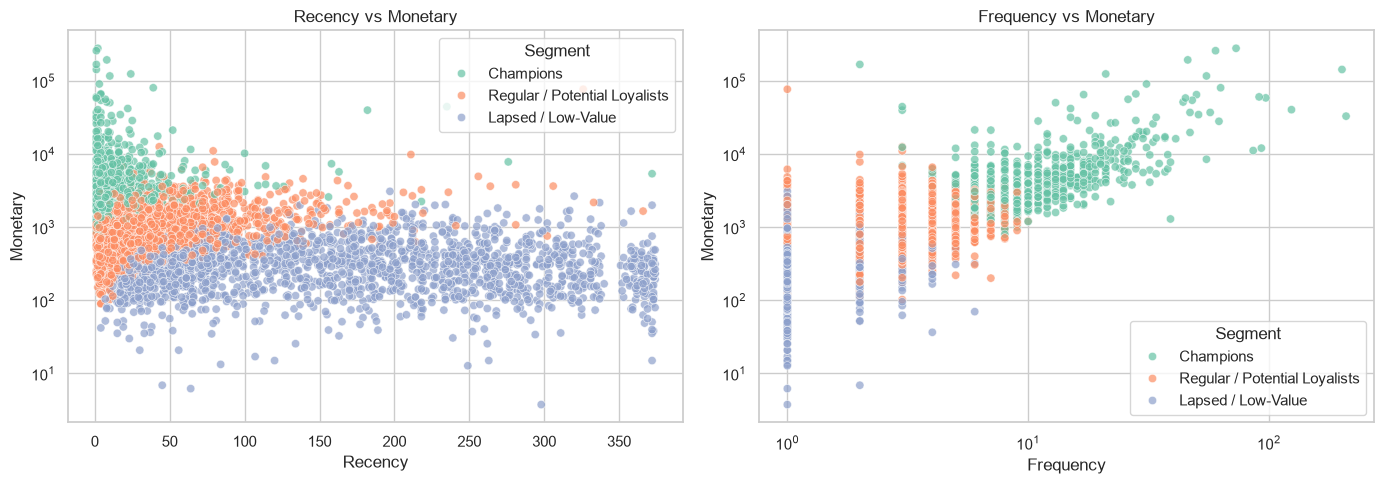

In [12]:
# Cluster scatter plots for two feature combinations
order = ["Champions", "Regular / Potential Loyalists", "Lapsed / Low-Value"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=rfm, x="Recency", y="Monetary", hue="Segment", hue_order=order,
                palette="Set2", alpha=0.7, ax=axes[0])
axes[0].set_title("Recency vs Monetary")
axes[0].set_yscale("log")

sns.scatterplot(data=rfm, x="Frequency", y="Monetary", hue="Segment", hue_order=order,
                palette="Set2", alpha=0.7, ax=axes[1])
axes[1].set_title("Frequency vs Monetary")
axes[1].set_xscale("log")
axes[1].set_yscale("log")

plt.tight_layout()
plt.show()

**Observations**
- Champions sit in the top-left of Recency vs Monetary (bought recently, spend a lot) and at the top-right of Frequency vs Monetary (many orders, high spend).
- Lapsed / Low-Value customers sit at the bottom of both charts: mostly one or two orders and low spend, spread across all recency values.
- Regular customers sit in between, so they are the natural group to move up toward Champions.
- A log scale is used for Monetary and Frequency so that the large spread of values stays readable.

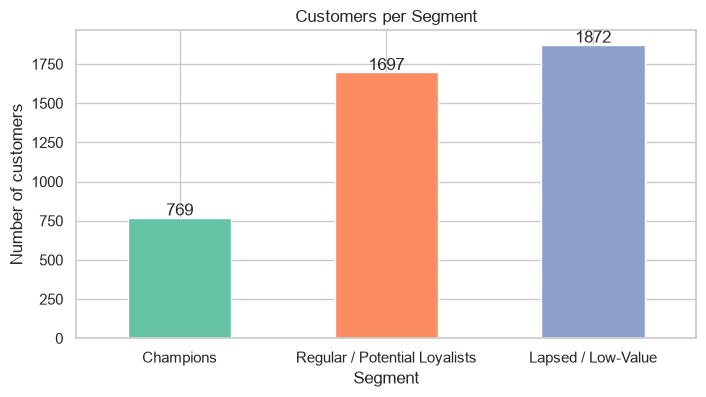

In [13]:
# Number of customers per segment
counts = rfm["Segment"].value_counts().reindex(order)

ax = counts.plot(kind="bar", color=sns.color_palette("Set2"), figsize=(8, 4))
for i, v in enumerate(counts):
    ax.text(i, v + 15, str(v), ha="center")
ax.set_xlabel("Segment")
ax.set_ylabel("Number of customers")
ax.set_title("Customers per Segment")
plt.xticks(rotation=0)
plt.show()

**Observation:** Lapsed / Low-Value is the largest group, followed by Regular customers, while Champions are the smallest group. The next table shows how revenue is distributed compared to customer counts.

In [14]:
# Customers vs revenue share per segment
profile.set_index("Segment").loc[order, ["Customers", "Customer_Share_%", "Revenue_Share_%"]]

,Customers,Customer_Share_%,Revenue_Share_%
Segment,,,
Champions,769,17.70,68.30
Regular / Potential Loyalists,1697,39.10,24.10
Lapsed / Low-Value,1872,43.20,7.60


## 8. Insights and marketing recommendations

**Champions (769 customers, about 17.7%)**
They bought very recently (about 17 days ago on average), order often (about 13 orders) and spend the most (about £7,900 each).
*Recommendation:* VIP or loyalty programme, early access to new products, exclusive offers and referral rewards. Avoid heavy discounts, since they already buy frequently.

**Regular / Potential Loyalists (1,697 customers, about 39.1%)**
Moderately recent (about 44 days), around 3 orders and about £1,260 average spend.
*Recommendation:* cross-sell and bundle offers, "buy more, save more" thresholds, and reminder emails to move them toward Champions.

**Lapsed / Low-Value (1,872 customers, about 43.2%)**
Last purchase about 167 days ago, mostly one-time buyers (about 1.4 orders) and the lowest spend (about £361).
*Recommendation:* win-back email campaign with a limited-time discount and a short feedback survey to learn why they stopped buying. Keep marketing spend low for this group.

**Key takeaway:** Champions are only about 18% of customers but generate about two thirds of total revenue (see the Revenue_Share_% column above), so retaining them is the top priority.

## 9. Conclusion

- RFM features with K-Means (K=3) separated 4,338 customers into three clearly different segments.
- Log transformation and scaling were essential because the raw RFM data is highly skewed.
- K=3 was selected using the Elbow method and silhouette scores, balancing statistical quality with business usefulness.
- Each segment has a specific recommended action, from retention (Champions) to growth (Regular) to win-back (Lapsed).

In [15]:
# Save the final segment table for reuse (for example in a dashboard)
rfm.to_csv("rfm_segments.csv", index=False)
print("Saved rfm_segments.csv with", len(rfm), "customers")

Saved rfm_segments.csv with 4338 customers
